# **PRAKTIKUM 1**

In [30]:
import pandas as pd
import io
import matplotlib.pyplot as plt
import seaborn as sns

**Langkah 1 - Load Data**

In [31]:
df = pd.read_csv('../Data/jakarta_house.csv')

df.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


**Langkah 2 - Pengecekan Data**

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  str    
 3   city           10000 non-null  str    
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      9997 non-null   float64
 8   building_area  9995 non-null   float64
dtypes: float64(2), int64(5), str(2)
memory usage: 937.6 KB


In [33]:
df.isnull().sum()

index            0
price            0
district         0
city             0
bed_rooms        0
bath_rooms       0
carport          0
land_area        3
building_area    5
dtype: int64

**Langkah 3 - Imputasi**

In [34]:
# land_area - mean
df['land_area'] = df['land_area'].fillna(df['land_area'].mean())

# building_area - mean
df['building_area'] = df['building_area'].fillna(df['building_area'].mean())


**Langkah 4 - Validasi Hasil**

In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  str    
 3   city           10000 non-null  str    
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      10000 non-null  float64
 8   building_area  10000 non-null  float64
dtypes: float64(2), int64(5), str(2)
memory usage: 937.6 KB


In [36]:
df.isnull().sum()

index            0
price            0
district         0
city             0
bed_rooms        0
bath_rooms       0
carport          0
land_area        0
building_area    0
dtype: int64

**Langkah 5 - Ekstraksi Fitur**

In [37]:
# === EKSTRAKSI FITUR ===

# 1. TotalRooms: total jumlah kamar (bed_rooms + bath_rooms)
df["TotalRooms"] = df["bed_rooms"] + df["bath_rooms"]

# 2. PricePerMeter: bagi harga dengan luas bangunan
df["PricePerMeter"] = df["price"] / df["building_area"]

print("✅ Hasil Ekstraksi fitur ")
df[["city", "district", "bed_rooms", "bath_rooms", "TotalRooms", "price", "building_area", "PricePerMeter"]].head()

✅ Hasil Ekstraksi fitur 


,city,district,bed_rooms,bath_rooms,TotalRooms,price,building_area,PricePerMeter
0,Jakarta Barat,Citra Garden,2,4,6,5900000000,350.0,1.685714e+07
1,Jakarta Barat,Jelambar,4,2,6,2700000000,225.0,1.200000e+07
2,Jakarta Barat,Jelambar,3,3,6,2200000000,140.0,1.571429e+07
3,Jakarta Barat,Jelambar,3,2,5,1900000000,120.0,1.583333e+07
4,Jakarta Barat,Tanjung Duren,4,3,7,2100000000,108.0,1.944444e+07


**Langkah 6 - Visualisasi Hasil Ektraksi Fitur**

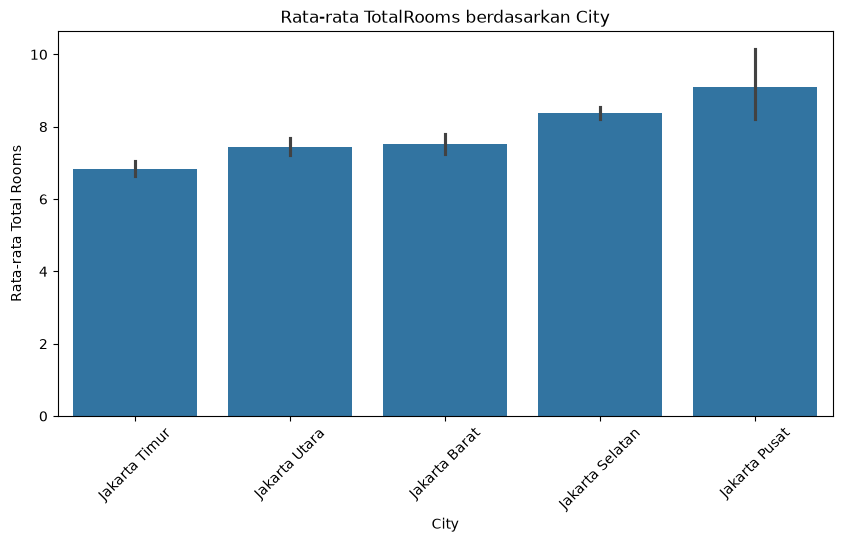

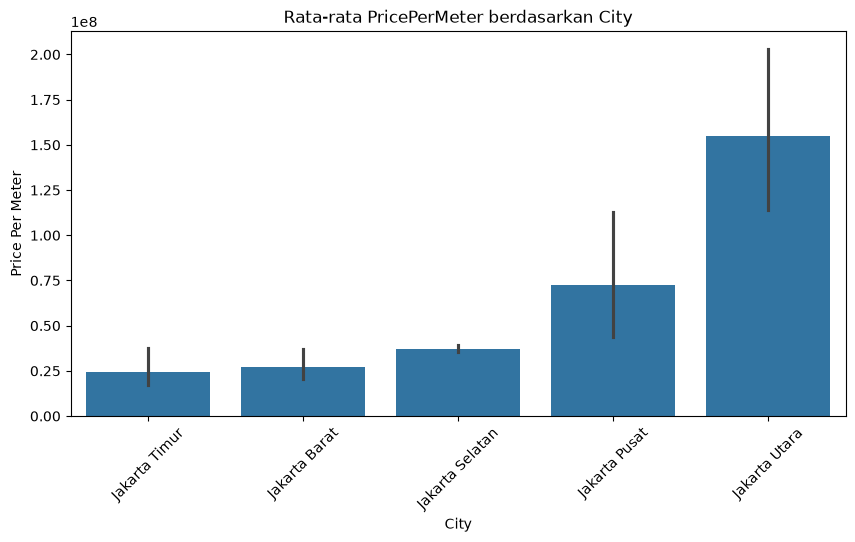

In [38]:
# === VISUALISASI FITUR HASIL EKSTRAKSI ===

# 1. Rata-rata TotalRooms berdasarkan City (lebih simpel & rapi berdasarkan wilayah)
plt.figure(figsize=(10, 5))
sns.barplot(x="city", y="TotalRooms", data=df,
            order=df.groupby("city")["TotalRooms"].mean().sort_values().index)
plt.title("Rata-rata TotalRooms berdasarkan City")
plt.xlabel("City")
plt.ylabel("Rata-rata Total Rooms")
plt.xticks(rotation=45)
plt.show()

# 2. Rata-rata PricePerMeter berdasarkan City
plt.figure(figsize=(10, 5))
sns.barplot(x="city", y="PricePerMeter", data=df,
            order=df.groupby("city")["PricePerMeter"].mean().sort_values().index)
plt.title("Rata-rata PricePerMeter berdasarkan City")
plt.xlabel("City")
plt.ylabel("Price Per Meter")
plt.xticks(rotation=45)
plt.show()

# **PRAKTIKUM 2**

**Langkah 0 - Load Library**

In [39]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler

**Langkah 1 - Load Data**

In [40]:
df = pd.read_csv('../Data/jakarta_house.csv')
df.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


**Langkah 2 - Pre Processing Encoding City**

In [41]:
le = LabelEncoder()
df['city'] = le.fit_transform(df['city'])

**Langkah 3 - Verifikasi hasil encoding "city"**

In [42]:
print("=== Verifikasi Hasil Encoding 'city' ===")
print(df[['city']].head(5))

=== Verifikasi Hasil Encoding 'city' ===
   city
0     0
1     0
2     0
3     0
4     0


**Langkah 4- Pre Processing Encoding "district"**

In [43]:
df['district'] = df['district'].astype(str)
le_district = LabelEncoder()
df['district'] = le_district.fit_transform(df['district'])

**Langkah 5 - Verifikasi hasil encoding "district"**

In [44]:
print("=== Verifikasi Hasil Encoding 'district' ===")
print(df[['district']].head(5), "\n")

=== Verifikasi Hasil Encoding 'district' ===
   district
0        39
1        74
2        74
3        74
4       234 



**Langkah 6 - Pre Processing Imputasi Data**

In [45]:
mean_land = df['land_area'].mean()
df['land_area'] = df['land_area'].fillna(mean_land)

mean_build = df['building_area'].mean()
df['building_area'] = df['building_area'].fillna(mean_build)

**Langkah 7 - Verifikasi Hasil Imputasi Data**

In [46]:
print("=== Jumlah Missing Value Setelah Imputasi ===")
print(df[['land_area', 'building_area']].isnull().sum(), "\n")

=== Jumlah Missing Value Setelah Imputasi ===
land_area        0
building_area    0
dtype: int64 



**Langkah 8 - Pre Processing Standarisasi**

In [47]:
scaler = StandardScaler()
df['building_area'] = scaler.fit_transform(df[['building_area']])

**Langkah 9 - Verifikasi Hasil Standarisasi**

In [48]:
print("=== Hasil Setelah Standardisasi 'building_area' ===")
print(df[['building_area']].head(10), "\n")

=== Hasil Setelah Standardisasi 'building_area' ===
   building_area
0       0.084005
1      -0.265578
2      -0.503295
3      -0.559228
4      -0.592788
5      -0.478125
6      -0.223628
7       0.313331
8       1.342504
9      -0.111762 



**Langkah 10 - Hasil setelah Pre Processing**

In [49]:
print("=== Hasil Preprocessing (5 baris pertama) ===")
df.head()

=== Hasil Preprocessing (5 baris pertama) ===


,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,39,0,2,4,2,250.0,0.084005
1,2,2700000000,74,0,4,2,0,100.0,-0.265578
2,3,2200000000,74,0,3,3,0,60.0,-0.503295
3,4,1900000000,74,0,3,2,0,60.0,-0.559228
4,5,2100000000,234,0,4,3,0,56.0,-0.592788


**Langkah 11 - Seleksi Fitur**

In [50]:
df = df[['price', 'city', 'district', 'building_area', 'land_area']]
df.head()

,price,city,district,building_area,land_area
0,5900000000,0,39,0.084005,250.0
1,2700000000,0,74,-0.265578,100.0
2,2200000000,0,74,-0.503295,60.0
3,1900000000,0,74,-0.559228,60.0
4,2100000000,0,234,-0.592788,56.0


# **PRAKTIKUM 3**

**RANDOM SPLIT**

**Langkah 1 - Load Data**

In [51]:
df = pd.read_csv('../Data/jakarta_house.csv')
df['land_area'] = df['land_area'].fillna(df['land_area'].mean())
df['building_area'] = df['building_area'].fillna(df['building_area'].mean())
df.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


**Langkah 2 - Split Data**

In [52]:
# Split data
from sklearn.model_selection import train_test_split

# Split data training dan dan lainnya
# data lainnya, akan kita split lagi menjadi validasi dan testing.
# Rasio yang akan kita gunakan adalah 8:1:1
df_train, df_unseen = train_test_split(df, test_size=0.2, random_state=0)

# Split lagi antara validasi dan testing
df_val, df_test = train_test_split(df_unseen, test_size=0.5, random_state=0)

# Cek masing-masing ukuran data

print(f'Jumlah data asli: {df.shape[0]}')
print(f'Jumlah data train: {df_train.shape[0]}')
print(f'Jumlah data val: {df_val.shape[0]}')
print(f'Jumlah data test: {df_test.shape[0]}')

# Cek rasio tiap label
print('=========')
print(f'Jumlah label data asli:\n{df.city.value_counts()}')
print(f'Jumlah label data train:\n{df_train.city.value_counts()}')
print(f'Jumlah label data val:\n{df_val.city.value_counts()}')
print(f'Jumlah label data test:\n{df_test.city.value_counts()}')

Jumlah data asli: 10000
Jumlah data train: 8000
Jumlah data val: 1000
Jumlah data test: 1000
Jumlah label data asli:
city
Jakarta Selatan    3379
Jakarta Barat      2622
Jakarta Utara      1739
Jakarta Timur      1690
Jakarta Pusat       570
Name: count, dtype: int64
Jumlah label data train:
city
Jakarta Selatan    2660
Jakarta Barat      2104
Jakarta Utara      1407
Jakarta Timur      1374
Jakarta Pusat       455
Name: count, dtype: int64
Jumlah label data val:
city
Jakarta Selatan    361
Jakarta Barat      274
Jakarta Utara      158
Jakarta Timur      157
Jakarta Pusat       50
Name: count, dtype: int64
Jumlah label data test:
city
Jakarta Selatan    358
Jakarta Barat      244
Jakarta Utara      174
Jakarta Timur      159
Jakarta Pusat       65
Name: count, dtype: int64


**STRATIFIED SPLIT**

**Langkah 1 - Load**

In [53]:
df2 = pd.read_csv('../Data/jakarta_house.csv')
df2['land_area'] = df2['land_area'].fillna(df2['land_area'].mean())
df2['building_area'] = df2['building_area'].fillna(df2['building_area'].mean())
df2.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


**Langkah 2 - Split Data**

In [54]:
# Split data
from sklearn.model_selection import train_test_split

# Split data training dan dan lainnya
# data lainnya, akan kita split lagi menjadi validasi dan testing.
# Rasio yang akan kita gunakan adalah 8:1:1
df2_train, df2_unseen = train_test_split(df2, test_size=0.2, random_state=0, stratify=df2['city'])

# Split lagi antara validasi dan testing
df2_val, df2_test = train_test_split(df2_unseen, test_size=0.5, random_state=0, stratify=df2_unseen['city'])

# Cek masing-masing ukuran data

print(f'Jumlah label data asli:\n{df2.city.value_counts()}')
print(f'Jumlah label data train:\n{df2_train.city.value_counts()}')
print(f'Jumlah label data val:\n{df2_val.city.value_counts()}')
print(f'Jumlah label data test:\n{df2_test.city.value_counts()}')

Jumlah label data asli:
city
Jakarta Selatan    3379
Jakarta Barat      2622
Jakarta Utara      1739
Jakarta Timur      1690
Jakarta Pusat       570
Name: count, dtype: int64
Jumlah label data train:
city
Jakarta Selatan    2703
Jakarta Barat      2098
Jakarta Utara      1391
Jakarta Timur      1352
Jakarta Pusat       456
Name: count, dtype: int64
Jumlah label data val:
city
Jakarta Selatan    338
Jakarta Barat      262
Jakarta Utara      174
Jakarta Timur      169
Jakarta Pusat       57
Name: count, dtype: int64
Jumlah label data test:
city
Jakarta Selatan    338
Jakarta Barat      262
Jakarta Utara      174
Jakarta Timur      169
Jakarta Pusat       57
Name: count, dtype: int64


**CORSS VALIDATION 1**

**Langkah 1 - Load**

In [55]:
df3 = pd.read_csv('../Data/jakarta_house.csv')
df3['land_area'] = df3['land_area'].fillna(df3['land_area'].mean())
df3['building_area'] = df3['building_area'].fillna(df3['building_area'].mean())
df3.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


**Langkah 2 - Split Data**

In [56]:
# Implementasi k-fold cross validation (random) dengan training dan testing saja
from sklearn.model_selection import KFold

# inisiasi obyek kfold
kf = KFold(n_splits=4)
print(f'Jumlah fold: {kf.get_n_splits()}')
print(f'Obyek KFold: {kf}')

# Lakukan splitting dengan KFold
kf_split = kf.split(df3)
print(f'Jumlah data df: {df3.shape[0]}')

# cek index data tiap fold
for train_index, test_index in kf_split:
    print(f'Index train: {train_index} | Index test: {test_index}')

Jumlah fold: 4
Obyek KFold: KFold(n_splits=4, random_state=None, shuffle=False)
Jumlah data df: 10000
Index train: [2500 2501 2502 ... 9997 9998 9999] | Index test: [   0    1    2 ... 2497 2498 2499]
Index train: [   0    1    2 ... 9997 9998 9999] | Index test: [2500 2501 2502 ... 4997 4998 4999]
Index train: [   0    1    2 ... 9997 9998 9999] | Index test: [5000 5001 5002 ... 7497 7498 7499]
Index train: [   0    1    2 ... 7497 7498 7499] | Index test: [7500 7501 7502 ... 9997 9998 9999]


**CROSS VALIDADTION 2**

**Langkah 1 - Load**

In [57]:
df4 = pd.read_csv('../Data/jakarta_house.csv')
df4['land_area'] = df4['land_area'].fillna(df4['land_area'].mean())
df4['building_area'] = df4['building_area'].fillna(df4['building_area'].mean())
df4.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


**Langkah 2 - Split Data**

In [58]:
# Implementasi k-fold cross validation (random) dengan training, validation, dan testing data
from sklearn.model_selection import train_test_split, KFold

# Split dulu antara data training dan testing dengan train_test_split
# Rasio 8:2 untuk training dan testing
df4_train, df4_test = train_test_split(df4, test_size=0.2, random_state=0)

# inisiasi obyek kfold
kf2 = KFold(n_splits=4)
print(f'Jumlah fold: {kf2.get_n_splits()}')
print(f'Obyek KFold: {kf2}')

# Lakukan splitting dengan KFold untuk data df_training
# Dengan acara ini, kita masih memiliki data testing untuk keperluan pengujian model
# namun tetap dapat melakukan evaluasi dengan menggunakan data validasi
kf2_split = kf2.split(df4_train)
print(f'Jumlah data df_train: {df4_train.shape[0]}')

# cek index data tiap fold
for train_index, test_index in kf2_split:
    print(f'Index train: {train_index} | Index test: {test_index}')

Jumlah fold: 4
Obyek KFold: KFold(n_splits=4, random_state=None, shuffle=False)
Jumlah data df_train: 8000
Index train: [2000 2001 2002 ... 7997 7998 7999] | Index test: [   0    1    2 ... 1997 1998 1999]
Index train: [   0    1    2 ... 7997 7998 7999] | Index test: [2000 2001 2002 ... 3997 3998 3999]
Index train: [   0    1    2 ... 7997 7998 7999] | Index test: [4000 4001 4002 ... 5997 5998 5999]
Index train: [   0    1    2 ... 5997 5998 5999] | Index test: [6000 6001 6002 ... 7997 7998 7999]


# **TUGAS PRAKTIKUM**

In [59]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

**Load Data**

In [60]:
df = pd.read_csv('../Data/jakarta_house.csv')
df['land_area'] = df['land_area'].fillna(df['land_area'].mean())
df['building_area'] = df['building_area'].fillna(df['building_area'].mean())

df.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


**1. Pisahkan antara variabel yang dapat digunakan dan variabel yang tidak dapat digunakan.**

In [61]:
# Variabel yang tidak digunakan
df = df.drop(['index'], axis=1)

# Cek hasil
df.head()

,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


**2. Lakukan proses encoding pada kolom kategorikal.**

In [62]:
le = LabelEncoder()

df['city'] = le.fit_transform(df['city'])
df['district'] = le.fit_transform(df['district'])

df[['city', 'district']].head()

,city,district
0,0,39
1,0,74
2,0,74
3,0,74
4,0,234


**3. Lakukan proses standardisasi pada semua kolom yang memiliki nilai numerik.**

In [63]:
# Memisahkan fitur dan target
X = df.drop('city', axis=1)

# Membuat objek StandardScaler
std = StandardScaler()

# Standardisasi data
X_scaled = std.fit_transform(X)

# Mengubah kembali ke DataFrame
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

# Menampilkan hasil
X_scaled.head()

,price,district,bed_rooms,bath_rooms,carport,land_area,building_area
0,-0.206558,-1.154122,-0.709440,0.165069,0.241542,-0.092697,0.084005
1,-0.366205,-0.650337,-0.079806,-0.524588,-0.905654,-0.391014,-0.265578
2,-0.391150,-0.650337,-0.394623,-0.179759,-0.905654,-0.470565,-0.503295
3,-0.406117,-0.650337,-0.394623,-0.524588,-0.905654,-0.470565,-0.559228
4,-0.396139,1.652679,-0.079806,-0.179759,-0.905654,-0.478520,-0.592788


**4. Lakukan proses stratified split data untuk membuat data latih dan data uji dengan rasio 80:20.**

In [64]:
from sklearn.model_selection import train_test_split

# Memisahkan fitur dan target
X = X_scaled # Fitur
y = df['city'] # Target

# Stratified split 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Melihat jumlah data
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (8000, 7)
X_test  : (2000, 7)
y_train : (8000,)
y_test  : (2000,)
